# Preliminary experiment — simulating the *Drosophila melanogaster* JO auditory circuit with Brian2

### Methodological validation ahead of the main comparative experiment (biological SNN vs. Erdős–Rényi control, both under STDP)

**Trabajo de Integración Curricular** — *Bio-Inspired Neuromorphic Coding for Efficient Edge AI with Spiking Neural Networks* — UTPL 2026

---

## What we replicate, and why it matters

This notebook picks up two pieces of work that build on one another.

- **Shiu et al. (2024, *Nature*).** They ran the whole *Drosophila* connectome (FlyWire) as a leaky integrate-and-fire (LIF) network in Brian2, **without modifying a single weight**. Biological topology on its own reproduced around 95 % of the motor behavior recorded in live flies.
- **Eon Systems PBC (March 2026).** They pushed the model into a full embodied brain emulation (~127,400 neurons) inside a virtual body (MuJoCo / NeuroMechFly v2), where several behaviors emerged.

Both share one limitation, and their own authors say so. The synaptic weights are static, so the network never learns and never adapts. Our project adds the piece they left out, **STDP** (*spike-timing-dependent plasticity*).

## What this preliminary experiment is for

Before putting plasticity on top of the biological topology, we wanted three things confirmed.

1. That the **JO subgraph** extracted from the FlyWire connectome loads correctly. It is the product of our EDA notebook, CRISP-DM phases 2 and 3.
2. That Brian2 simulates it as a LIF network and yields **coherent activity**, reproducing the baseline condition of Shiu et al. We call this the **static-weight run**.
3. That adding **STDP + WTA** produces **measurable change** in the weights and in the dynamics of the network. That is the **STDP run**.

What comes out of it is the reference baseline against which the Erdős–Rényi network will be compared in the main experiment. There is a plainer motive too. If the LIF implementation without plasticity does not produce reasonable activity, the fault lies in the extraction or in the configuration, and we would rather find that out now than later.

## Data source

We read the subgraph our EDA notebook already extracted and cleaned (`../exploratory-data-analysis.ipynb`), straight from its output folder.

| File | Contents |
|---|---|
| `jo_nodes_filtered.csv` | Subgraph nodes (JO neurons plus their second-order AMMC partners), with hierarchical annotation. |
| `jo_edges_filtered.csv` | Filtered directed connections (synaptic weight ≥ 5), carrying neurotransmitter and functional polarity. |

> The filtered subgraph holds **1,239 nodes** (269 auditory JO neurons) and **20,059 directed connections**, with polarity already assigned following Eckstein et al. (2024). The polarity labels are stored in the CSV as written by the EDA notebook, so they appear verbatim as `Excitatory` (ACH), `Inhibitory` (GABA/GLUT) and `Modulatory` (SER/DA/OCT).


## 0. Environment setup

### 0.1. Dependencies

The notebook runs inside the project virtual environment. At its core sits **Brian2**, the SNN simulator, next to the usual scientific stack (`numpy`, `pandas`, `matplotlib`) and `networkx` for inspecting the topology. The cell below installs whatever might be missing, and it is idempotent.


In [1]:
# Idempotent install. If the packages are already there, pip just verifies them.
%pip install -q brian2 networkx pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


### 0.2. Imports, paths and reproducibility

We follow the style of Shiu et al. with `from brian2 import *`, which brings in physical units such as `mV`, `ms` and `nA` together with the simulation functions. The **seed** is fixed so the simulation reproduces, and the output folders are prepared up front.


In [2]:
import warnings
warnings.filterwarnings('ignore')

from brian2 import *      # NeuronGroup, Synapses, units (mV, ms, nA...), run, seed
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import json
from pathlib import Path

# Paths (relative to the notebook directory: preliminary-experiments/)
DATA_DIR = Path('../outputs')                                # CSVs written by the EDA notebook
ART_DIR  = Path('artifacts'); ART_DIR.mkdir(exist_ok=True)   # arrays for Brian2
OUT_DIR  = Path('outputs');   OUT_DIR.mkdir(exist_ok=True)   # figures and metrics

# Reproducibility
SEED = 42
np.random.seed(SEED)

# Consistent figure style
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'axes.titleweight': 'bold', 'font.size': 10})

print('Environment ready.')
print('  brian2 ', __import__('brian2').__version__)
print('  numpy  ', np.__version__)
print('  pandas ', pd.__version__)
print('  data files? nodes =', (DATA_DIR/'jo_nodes_filtered.csv').exists(),
      '| edges =', (DATA_DIR/'jo_edges_filtered.csv').exists())

Environment ready.
  brian2  2.10.1
  numpy   2.4.6
  pandas  3.0.3
  data files? nodes = True | edges = True


## 1. Loading and characterizing the JO subgraph

We load the two subgraph files. A reminder of where they come from (our EDA notebook).

- The **JO neurons** were isolated with the taxonomy of Schlegel et al. (2024), `super_class = sensory ∧ class = mechanosensory ∧ sub_class = auditory` (JO-A and JO-B, the sound sensors covering 10–1000 Hz).
- We then added their **first-order postsynaptic partners**, interneurons of the AMMC (*Antennal Mechanosensory and Motor Center*), so that the circuit has dynamics worth simulating.
- Connections were filtered at **synaptic weight ≥ 5 contacts**, which throws away segmentation noise, and **functional polarity** was assigned from the predicted neurotransmitter (Eckstein et al., 2024).


In [3]:
nodes = pd.read_csv(DATA_DIR/'jo_nodes_filtered.csv')
edges = pd.read_csv(DATA_DIR/'jo_edges_filtered.csv')

# Make sure is_jo is boolean (some exports store it as text)
if nodes['is_jo'].dtype != bool:
    nodes['is_jo'] = nodes['is_jo'].astype(str).str.lower().map({'true': True, 'false': False})

print(f'Subgraph nodes:             {len(nodes):,}')
print(f'  - JO neurons (is_jo):     {int(nodes["is_jo"].sum())}')
print(f'  - second-order partners:  {int((~nodes["is_jo"]).sum())}')
print(f'Directed connections:       {len(edges):,}')
print('\nFunctional polarity of the connections:')
print(edges['polarity'].value_counts().to_string())
print('\nPredicted neurotransmitter:')
print(edges['nt'].value_counts().to_string())
print('\nSynaptic weight (contacts per connection):')
print(edges['weight'].describe().to_string())
edges.head()

Subgraph nodes:             1,239
  - JO neurons (is_jo):     269
  - second-order partners:  970
Directed connections:       20,059

Functional polarity of the connections:
polarity
Inhibitory    10674
Excitatory     8940
Modulatory        445

Predicted neurotransmitter:
nt
ACH     8940
GABA    8601
GLUT    2073
SER      295
DA       127
OCT       23

Synaptic weight (contacts per connection):
count    20059.000000
mean        16.850940
std         20.367109
min          5.000000
25%          6.000000
50%         10.000000
75%         19.000000
max        347.000000


,pre,post,polarity,weight,nt
0,720575940627410944,720575940609513841,Excitatorio,9,ACH
1,720575940627410944,720575940611674265,Excitatorio,23,ACH
2,720575940627410944,720575940612016498,Excitatorio,7,ACH
3,720575940627410944,720575940612054425,Excitatorio,5,ACH
4,720575940627410944,720575940613418547,Excitatorio,6,ACH


### 1.1. Graphical characterization

Two quick diagnostics before simulating. The first is the excitation/inhibition balance, which decides whether the network can settle or drifts toward saturation. The second is the distribution of synaptic weight, whose long tail is typical of FlyWire and is the reason we normalize weights before feeding them into Brian2.


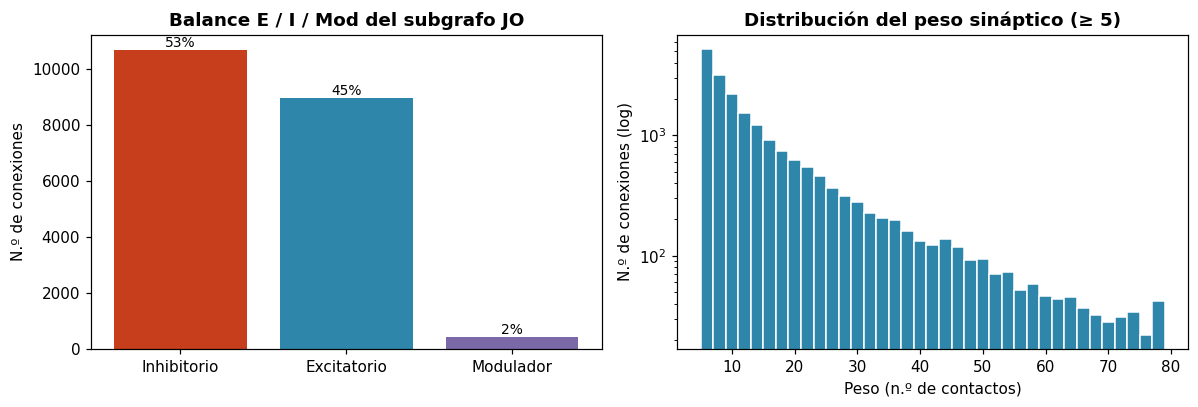

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

pol = edges['polarity'].value_counts()
# Polarity labels come from the CSV, so they keep the Spanish spelling used by the EDA notebook.
colmap = {'Excitatory': '#2E86AB', 'Inhibitory': '#C73E1D', 'Modulatory': '#7B68A6'}
ax[0].bar(pol.index, pol.values, color=[colmap.get(k, '#888') for k in pol.index])
ax[0].set_title('E / I / Mod balance of the JO subgraph'); ax[0].set_ylabel('Number of connections')
for i, v in enumerate(pol.values):
    ax[0].text(i, v, f'{100*v/pol.sum():.0f}%', ha='center', va='bottom', fontsize=9)

ax[1].hist(edges['weight'], bins=np.arange(5, 80, 2), color='#2E86AB', edgecolor='white')
ax[1].set_yscale('log'); ax[1].set_title('Synaptic weight distribution (≥ 5)')
ax[1].set_xlabel('Weight (number of contacts)'); ax[1].set_ylabel('Number of connections (log)')

fig.tight_layout(); fig.savefig(OUT_DIR/'fig01_subgraph_characterization.png'); plt.show()

## 2. Translating the topology into Brian2 format

Brian2 works with integer indices `0..N-1`, not with the 18-digit FlyWire `root_id`. So we build

- a **mapping** `root_id → index`;
- the vectors `pre_indices`, `post_indices` (connections) and `weights`;
- the vector `syn_types` (`+1` excitatory, `−1` inhibitory) derived from polarity;
- the **indices of the sensory JO neurons**, which are where the auditory stimulus enters.

> The **modulators** (SER/DA/OCT, roughly 2 %) are treated as weak excitatory synapses in this preliminary experiment, since slow neuromodulation is not modelled yet. Their effect on the dynamics is marginal.


In [5]:
# Index space: nodes actually connected in the filtered subgraph
node_ids = sorted(set(edges['pre']).union(set(edges['post'])))
id_to_idx = {nid: i for i, nid in enumerate(node_ids)}
N = len(node_ids)

# Connections -> Brian2 indices
pre_idx  = edges['pre'].map(id_to_idx).to_numpy(np.int32)
post_idx = edges['post'].map(id_to_idx).to_numpy(np.int32)
weights  = edges['weight'].to_numpy(np.float32)

# Polarity -> synaptic type (+1 excitatory, -1 inhibitory)
pol_map = {'Excitatory': 1, 'Inhibitory': -1, 'Modulatory': 1}
syn_types = edges['polarity'].map(pol_map).fillna(1).to_numpy(np.int32)

# Indices of the sensory JO neurons (input to the auditory circuit)
jo_root = set(nodes.loc[nodes['is_jo'], 'root_id'])
jo_indices = np.array([id_to_idx[n] for n in node_ids if n in jo_root], dtype=np.int32)

# Persist the arrays so both simulation runs can reuse them
np.save(ART_DIR/'pre_indices.npy',  pre_idx)
np.save(ART_DIR/'post_indices.npy', post_idx)
np.save(ART_DIR/'weights.npy',      weights)
np.save(ART_DIR/'syn_types.npy',    syn_types)
np.save(ART_DIR/'jo_indices.npy',   jo_indices)
json.dump({'N_neurons': N, 'N_jo': int(len(jo_indices))},
          open(ART_DIR/'id_mapping.json', 'w'), indent=2)

print(f'Neurons (nodes) in the simulation: {N}')
print(f'  of which sensory JO:             {len(jo_indices)}')
print(f'Total synapses:                    {len(pre_idx):,}')
print(f'  excitatory (+1):                 {int((syn_types==1).sum()):,}')
print(f'  inhibitory (-1):                 {int((syn_types==-1).sum()):,}')
print('Arrays exported to ./artifacts/')

Neurons (nodes) in the simulation: 1239
  of which sensory JO:             269
Total synapses:                    20,059
  excitatory (+1):                 9,385
  inhibitory (-1):                 10,674
Arrays exported to ./artifacts/


## 3. Static-weight run — LIF without plasticity (replicating Shiu et al. 2024)

This run reproduces the **baseline condition**, the biological connectome executed with static weights and no learning at all. It is the equivalent of what Shiu et al. did and, by extension, of what Eon Systems did.

### 3.1. Neuron model

Every neuron is a **LIF** unit. Its membrane potential evolves as

$$\tau_m \frac{dv}{dt} = -(v - V_{rest}) + R_m \, I_{syn}, \qquad \frac{dI_{syn}}{dt} = -\frac{I_{syn}}{\tau_{syn}}$$

When $v$ crosses the threshold $V_{thresh}$ a spike is emitted and $v$ resets to $V_{reset}$, followed by a refractory period $\tau_{ref}$. The synaptic current $I_{syn}$ receives a jump at each presynaptic spike, positive for an excitatory synapse and negative for an inhibitory one, and decays with $\tau_{syn}$.

**Sensory input.** A Poisson group at 100 Hz injects current directly onto the **JO neurons**, which are the real sensory afferents of the circuit. That is more faithful than injecting into arbitrary indices. In the main experiment this rate will vary with the actual auditory stimulus.

**Weight normalization.** Connectome weights (`syn_count`, from 5 to 347 contacts) have a very long tail. We normalize by dividing by the **mean** rather than by the maximum, so the typical weight lands near 1 and the real dynamic range survives. Recurrent transmission then still shapes the dynamics. Normalizing by the maximum flattens almost every weight to about 0.05 and the network goes silent.

**E/I balance.** The subgraph carries more inhibitory connections (10,674) than excitatory ones (9,385). To keep the network from shutting down, the recurrent inhibitory current is scaled to half the excitatory one (`w_scale_inh = 0.5 · w_scale`), a standard calibration when porting connectomes to rate-based models.

| Parameter | Value | Meaning |
|---|---|---|
| `tau_m` | 10 ms | membrane time constant |
| `V_rest` / `V_reset` | −65 mV | resting potential / potential after a spike |
| `V_thresh` | −52 mV | firing threshold |
| `tau_ref` | 2 ms | refractory period |
| `R_m` | 10 MΩ | membrane resistance |
| `tau_syn` | 5 ms | synaptic time constant |
| `w_scale` (exc) | 1.5 nA | scale of the recurrent excitatory current |
| `w_scale_inh` | 0.75 nA | scale of the recurrent inhibitory current |
| `w_input` | 3.0 nA | fixed weight of the sensory input onto the JO neurons |
| `input_rate` | 100 Hz | rate of the Poisson input |


In [6]:
start_scope()
seed(SEED)
defaultclock.dt = 0.1 * ms

# --- Topology extracted from the connectome ---
pre_idx    = np.load(ART_DIR/'pre_indices.npy')
post_idx   = np.load(ART_DIR/'post_indices.npy')
weights    = np.load(ART_DIR/'weights.npy')
syn_types  = np.load(ART_DIR/'syn_types.npy')
jo_indices = np.load(ART_DIR/'jo_indices.npy')
N = int(max(pre_idx.max(), post_idx.max())) + 1

# --- Physiological LIF parameters ---
tau_m = 10*ms; V_rest = -65*mV; V_thresh = -52*mV; V_reset = -65*mV
tau_ref = 2*ms; R_m = 10*Mohm; tau_syn = 5*ms
w_scale     = 1.5*nA    # recurrent excitatory synaptic current
w_scale_inh = 0.75*nA   # recurrent inhibitory current (0.5 * w_scale)
w_input     = 3.0*nA    # fixed weight of the sensory input onto the JO neurons
T_sim       = 1000*ms   # simulation duration

eqs_lif = '''
dv/dt     = (-(v - V_rest) + R_m*I_syn)/tau_m : volt (unless refractory)
dI_syn/dt = -I_syn/tau_syn                    : amp
'''
NS = {'V_rest': V_rest, 'V_thresh': V_thresh, 'V_reset': V_reset,
      'tau_m': tau_m, 'R_m': R_m, 'tau_syn': tau_syn}

# --- JO neuron population ---
G = NeuronGroup(N, eqs_lif, threshold='v>V_thresh', reset='v=V_reset',
                refractory=tau_ref, method='euler', namespace=NS)
G.v = V_rest + np.random.uniform(0, 1, N) * (V_thresh - V_rest)  # avoids initial synchrony
G.I_syn = 0*nA

# --- Poisson sensory input onto the JO neurons ---
G_in = PoissonGroup(len(jo_indices), rates=100*Hz)
S_in = Synapses(G_in, G, on_pre='I_syn_post += w_input', namespace={'w_input': w_input})
S_in.connect(i=np.arange(len(jo_indices)), j=jo_indices)   # one-to-one onto each JO neuron

# --- Internal connectome synapses (static weights, normalized to mean 1) ---
w_norm = weights / weights.mean()   # mean = 1; preserves the real dynamic range
exc = syn_types == 1
inh = syn_types == -1

S_exc = Synapses(G, G, model='w:1', on_pre='I_syn_post += w_scale*w', namespace={'w_scale': w_scale})
S_exc.connect(i=pre_idx[exc], j=post_idx[exc]); S_exc.w = w_norm[exc]

S_inh = Synapses(G, G, model='w:1', on_pre='I_syn_post -= w_scale_inh*w', namespace={'w_scale_inh': w_scale_inh})
S_inh.connect(i=pre_idx[inh], j=post_idx[inh]); S_inh.w = w_norm[inh]

# --- Monitors ---
spk  = SpikeMonitor(G)
rate = PopulationRateMonitor(G)
rec  = [int(x) for x in jo_indices[:3]]
st   = StateMonitor(G, ['v', 'I_syn'], record=rec)

print(f'Static-weight run — LIF, no plasticity | N={N}  synapses={len(pre_idx):,}  '
      f'(exc={int(exc.sum())} inh={int(inh.sum())})')
run(T_sim, report='text')

active = len(set(np.array(spk.i)))
print(f'\nTotal spikes: {spk.num_spikes} | mean rate: {spk.num_spikes/N/float(T_sim/second):.2f} Hz '
      f'| active neurons: {active} ({100*active/N:.1f}%)')

WARNING    Removing unsupported flag '-march=native' from compiler flags. [brian2.codegen.cpp_prefs]


WARNING    'v' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value np.int64(445). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Static-weight run — LIF, no plasticity | N=1239  synapses=20,059  (exc=9385 inh=10674)


Starting simulation at t=0. s for a duration of 1. s


1. s (100%) simulated in < 1s



Total spikes: 24533 | mean rate: 19.80 Hz | active neurons: 567 (45.8%)


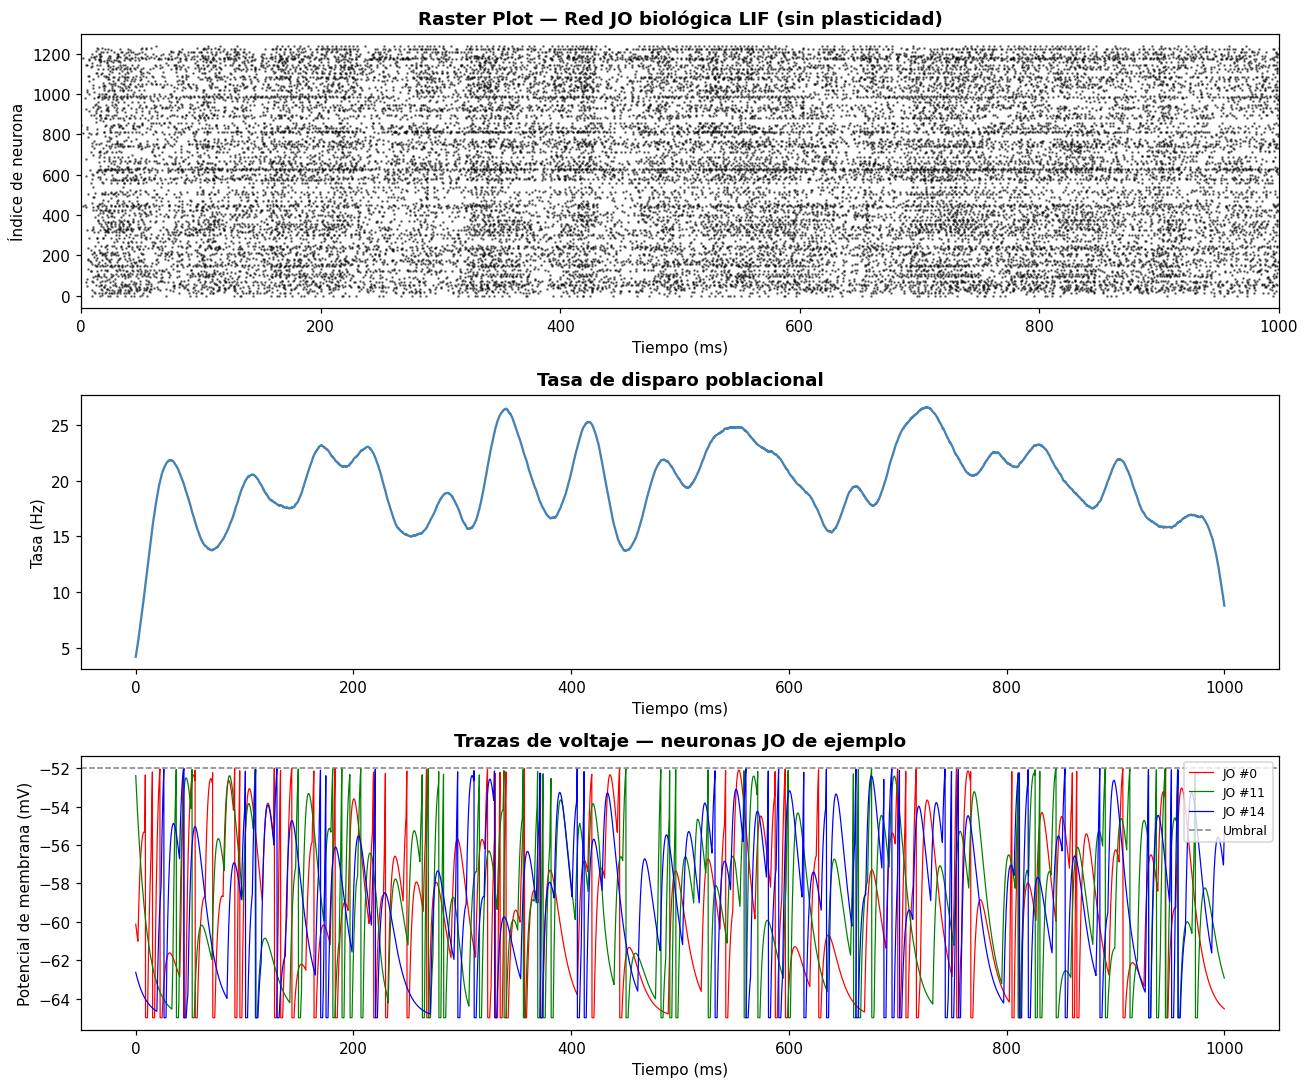

Metrics saved to artifacts/metrics_static_weights.json


{'fase': 'LIF sin plasticidad (réplica Shiu et al.)',
 'N_neuronas': 1239,
 'N_sinapsis': 20059,
 'duracion_ms': 1000,
 'total_spikes': 24533,
 'tasa_media_hz': 19.800645682001615,
 'neuronas_activas': 567,
 'porcentaje_activo': 45.76271186440678}

In [7]:
# --- Static-weight run, figures ---
fig, ax = plt.subplots(3, 1, figsize=(12, 10))

ax[0].scatter(spk.t/ms, spk.i, s=0.5, c='black', alpha=0.5)
ax[0].set(xlabel='Time (ms)', ylabel='Neuron index', xlim=(0, 1000),
          title='Raster plot — biological JO network, LIF with static weights')

ax[1].plot(rate.t/ms, rate.smooth_rate(window='gaussian', width=10*ms)/Hz, color='steelblue')
ax[1].set(xlabel='Time (ms)', ylabel='Rate (Hz)', title='Population firing rate')

for k, c in zip(range(len(rec)), ['red', 'green', 'blue']):
    ax[2].plot(st.t/ms, st.v[k]/mV, color=c, lw=0.8, label=f'JO #{rec[k]}')
ax[2].axhline(V_thresh/mV, color='gray', ls='--', lw=1, label='Threshold')
ax[2].set(xlabel='Time (ms)', ylabel='Membrane potential (mV)',
          title='Voltage traces — sample JO neurons')
ax[2].legend(loc='upper right', fontsize=8)

fig.tight_layout(); fig.savefig(OUT_DIR/'fig02_lif_static_weights.png'); plt.show()

# --- Quantitative metrics (kept for the later comparison) ---
m1 = {'run': 'LIF with static weights (Shiu et al. replication)', 'N_neurons': N,
      'N_synapses': int(len(pre_idx)), 'duration_ms': int(T_sim/ms),
      'total_spikes': int(spk.num_spikes), 'mean_rate_hz': float(spk.num_spikes/N/float(T_sim/second)),
      'active_neurons': int(active), 'active_percent': float(100*active/N)}
json.dump(m1, open(ART_DIR/'metrics_static_weights.json', 'w'), indent=2)
print('Metrics saved to artifacts/metrics_static_weights.json')
m1

### 3.2. What to look for

Following Shiu et al. (2024), the expected picture is this.

- **Sparse but structured activity**, meaning not every neuron fires at once.
- A moderate **population firing rate**, in the range of units to tens of Hz. If it goes above roughly 100 Hz across the board, `w_scale` and `w_input` are too high.
- A **non-uniform raster plot**. There should be spatiotemporal structure, not a solid block.

If the network falls **silent** or **saturates**, adjust `w_scale` and `w_input`.


## 4. STDP run — LIF with STDP + WTA (our contribution)

Here we add **synaptic plasticity** on top of exactly the same biological topology. The expectation is that weights reorganize according to the activity patterns.

### 4.1. STDP rule (Song et al., 2000)

$$\Delta t = t_{post} - t_{pre}: \quad \Delta w = \begin{cases} A_+ \, e^{-\Delta t/\tau_+} & \Delta t > 0 \;\;(\text{LTP}) \\ -A_- \, e^{\Delta t/\tau_-} & \Delta t < 0 \;\;(\text{LTD}) \end{cases}$$

We implement it with the synaptic traces `apre` and `apost` declared `event-driven`, the canonical and efficient form in Brian2. Each presynaptic spike increments `apre` and applies the pending depression; each postsynaptic spike increments `apost` and applies the pending potentiation.

> The asymmetry $A_- > A_+$ is deliberate. It prevents unbounded potentiation and drives the network toward a stable weight distribution (Diehl & Cook, 2015). We use $A_+=0.05$ and $A_-=0.0525$, a learning rate well above the canonical 0.01, so that the effect becomes **measurable** within the short 1 s horizon of this preliminary experiment.

### 4.2. Winner-take-all (WTA)

A small inhibitory population receives excitation from every neuron and returns **global lateral inhibition**. That encourages specialization, with different neurons learning to respond to different patterns instead of all converging on the same one. The **inhibitory** synapses of the connectome stay **static**, since STDP acts only on the excitatory ones, as is usual in these models.


In [8]:
start_scope()
seed(SEED)
defaultclock.dt = 0.1 * ms

# --- Topology ---
pre_idx    = np.load(ART_DIR/'pre_indices.npy')
post_idx   = np.load(ART_DIR/'post_indices.npy')
weights    = np.load(ART_DIR/'weights.npy')
syn_types  = np.load(ART_DIR/'syn_types.npy')
jo_indices = np.load(ART_DIR/'jo_indices.npy')
N = int(max(pre_idx.max(), post_idx.max())) + 1

# --- LIF parameters (identical to the static-weight run) ---
tau_m = 10*ms; V_rest = -65*mV; V_thresh = -52*mV; V_reset = -65*mV
tau_ref = 2*ms; R_m = 10*Mohm; tau_syn = 5*ms
w_scale = 1.5*nA; w_scale_inh = 0.75*nA; w_input = 3.0*nA
T_sim = 1000*ms

# --- STDP parameters ---
# Learning rate above the canonical value (0.01) so that the change is measurable
# within the short horizon of this preliminary experiment (1 s of simulation).
taupre = 20*ms; taupost = 20*ms
Aplus = 0.05; Aminus = 0.0525; wmax = 4.0   # weight upper bound (initial mean is ~1)

eqs_lif = '''
dv/dt     = (-(v - V_rest) + R_m*I_syn)/tau_m : volt (unless refractory)
dI_syn/dt = -I_syn/tau_syn                    : amp
'''
NS = {'V_rest': V_rest, 'V_thresh': V_thresh, 'V_reset': V_reset,
      'tau_m': tau_m, 'R_m': R_m, 'tau_syn': tau_syn}

G = NeuronGroup(N, eqs_lif, threshold='v>V_thresh', reset='v=V_reset',
                refractory=tau_ref, method='euler', namespace=NS)
G.v = V_rest + np.random.uniform(0, 1, N) * (V_thresh - V_rest); G.I_syn = 0*nA

# --- Poisson input onto the JO neurons ---
G_in = PoissonGroup(len(jo_indices), rates=100*Hz)
S_in = Synapses(G_in, G, on_pre='I_syn_post += w_input', namespace={'w_input': w_input})
S_in.connect(i=np.arange(len(jo_indices)), j=jo_indices)

w_norm = weights / weights.mean()   # mean = 1; preserves the real dynamic range
exc = syn_types == 1
inh = syn_types == -1

# --- Excitatory synapses WITH STDP (event-driven traces on the synapse) ---
stdp_model = '''
w : 1
dapre/dt  = -apre/taupre   : 1 (event-driven)
dapost/dt = -apost/taupost : 1 (event-driven)
'''
stdp_on_pre = '''
I_syn_post += w_scale*w
apre += Aplus
w = clip(w + apost, 0, wmax)
'''
stdp_on_post = '''
apost += -Aminus
w = clip(w + apre, 0, wmax)
'''
S_exc = Synapses(G, G, model=stdp_model, on_pre=stdp_on_pre, on_post=stdp_on_post,
                 namespace={'w_scale': w_scale, 'taupre': taupre, 'taupost': taupost,
                            'Aplus': Aplus, 'Aminus': Aminus, 'wmax': wmax})
S_exc.connect(i=pre_idx[exc], j=post_idx[exc])
S_exc.w = np.clip(w_norm[exc], 0, wmax)   # bounded to [0, wmax] for STDP
w_init = np.array(S_exc.w[:])          # initial weights (kept for comparison)

# --- Inhibitory synapses: static ---
S_inh = Synapses(G, G, model='w:1', on_pre='I_syn_post -= w_scale_inh*w', namespace={'w_scale_inh': w_scale_inh})
S_inh.connect(i=pre_idx[inh], j=post_idx[inh]); S_inh.w = w_norm[inh]

# --- WTA: lateral inhibition through a small inhibitory population ---
N_wta = min(N, 50)
G_inh = NeuronGroup(N_wta, eqs_lif, threshold='v>V_thresh', reset='v=V_reset',
                    refractory=tau_ref, method='euler', namespace=NS)
G_inh.v = V_rest; G_inh.I_syn = 0*nA
S_e2i = Synapses(G, G_inh, on_pre='I_syn_post += wta_exc', namespace={'wta_exc': 1.0*nA})
S_e2i.connect(j='i % N_wta')
S_i2e = Synapses(G_inh, G, on_pre='I_syn_post -= wta_inh', namespace={'wta_inh': 0.5*nA})
S_i2e.connect()                         # all-to-all (global lateral inhibition)

# --- Monitors ---
spk  = SpikeMonitor(G)
rate = PopulationRateMonitor(G)
n_rec = min(100, int(exc.sum()))
wmon = StateMonitor(S_exc, 'w', record=range(n_rec))

print(f'STDP run — LIF + STDP + WTA | exc={int(exc.sum())} inh={int(inh.sum())} WTA={N_wta}')
run(T_sim, report='text')

w_final = np.array(S_exc.w[:])
active = len(set(np.array(spk.i)))
print(f'\nTotal spikes: {spk.num_spikes} | mean rate: {spk.num_spikes/N/float(T_sim/second):.2f} Hz '
      f'| active: {active}')
print(f'Mean weight before: {w_init.mean():.3f}  ->  after: {w_final.mean():.3f}')

WARNING    'i' is an internal variable of group 'synapses_2', but also exists in the run namespace with the value 2. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'v' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value np.int64(445). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'v' is an internal variable of group 'neurongroup_2', but also exists in the run namespace with the value np.int64(445). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


STDP run — LIF + STDP + WTA | exc=9385 inh=10674 WTA=50


Starting simulation at t=0. s for a duration of 1. s


1. s (100%) simulated in < 1s



Total spikes: 6676 | mean rate: 5.39 Hz | active: 349


Mean weight before: 0.894  ->  after: 0.900


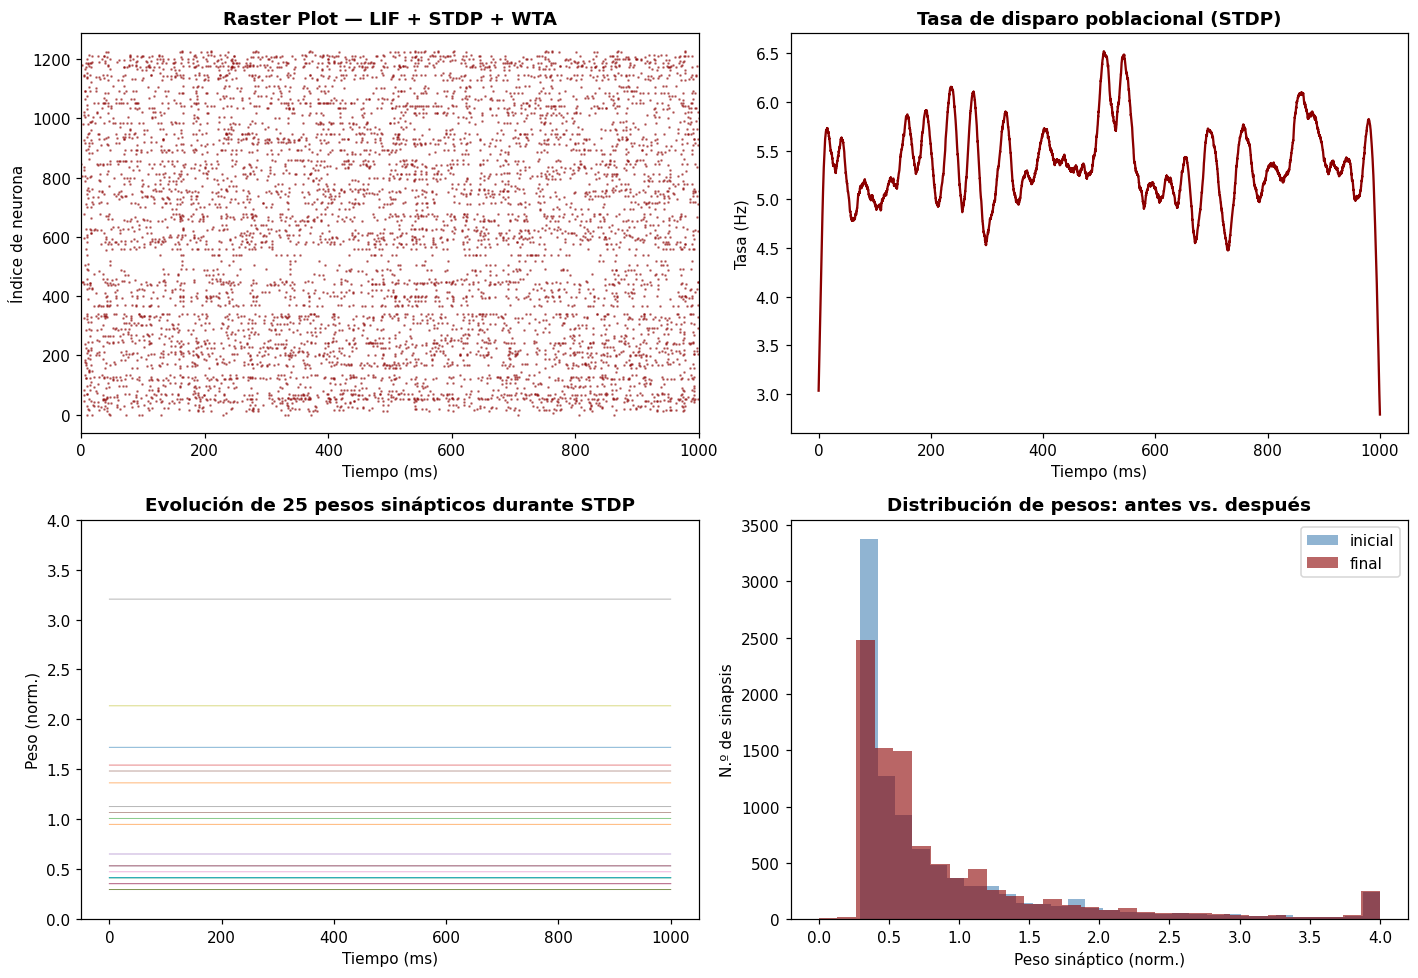

Metrics saved to artifacts/metrics_stdp.json


{'fase': 'LIF con STDP + WTA',
 'N_neuronas': 1239,
 'N_sinapsis_exc': 9385,
 'N_sinapsis_inh': 10674,
 'total_spikes': 6676,
 'tasa_media_hz': 5.388216303470541,
 'neuronas_activas': 349,
 'porcentaje_activo': 28.167877320419695,
 'peso_medio_inicial': 0.8935492071244204,
 'peso_medio_final': 0.90002999516513,
 'cambio_medio_dw': 0.006480788040709518,
 'cambio_abs_medio_dw': 0.00857801317571881,
 'std_dw': 0.06127676396786446,
 'sinapsis_potenciadas': 397,
 'sinapsis_deprimidas': 124,
 'sinapsis_modificadas_pct': 5.551411827384124}

In [9]:
# --- STDP run, figures ---
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

ax[0, 0].scatter(spk.t/ms, spk.i, s=0.5, c='darkred', alpha=0.5)
ax[0, 0].set(xlabel='Time (ms)', ylabel='Neuron index', xlim=(0, 1000),
             title='Raster plot — LIF + STDP + WTA')

ax[0, 1].plot(rate.t/ms, rate.smooth_rate(window='gaussian', width=10*ms)/Hz, color='darkred')
ax[0, 1].set(xlabel='Time (ms)', ylabel='Rate (Hz)', title='Population firing rate (STDP)')

n_show = min(25, wmon.w.shape[0])
for i in range(n_show):
    ax[1, 0].plot(wmon.t/ms, wmon.w[i], lw=0.6, alpha=0.6)
ax[1, 0].set(xlabel='Time (ms)', ylabel='Weight (norm.)', ylim=(0, wmax),
             title=f'Evolution of {n_show} synaptic weights under STDP')

ax[1, 1].hist(w_init, bins=30, alpha=0.6, label='before', color='steelblue')
ax[1, 1].hist(w_final, bins=30, alpha=0.6, label='after', color='darkred')
ax[1, 1].set(xlabel='Synaptic weight (norm.)', ylabel='Number of synapses',
             title='Weight distribution: before vs. after')
ax[1, 1].legend()

fig.tight_layout(); fig.savefig(OUT_DIR/'fig03_lif_with_stdp.png'); plt.show()

# --- STDP run metrics ---
# Per-synapse weight change (Delta w = final - initial). This measures the effect of
# STDP directly, which is the third goal of the preliminary experiment.
dw = w_final - w_init
m2 = {'run': 'LIF with STDP + WTA', 'N_neurons': N, 'N_synapses_exc': int(exc.sum()),
      'N_synapses_inh': int(inh.sum()), 'total_spikes': int(spk.num_spikes),
      'mean_rate_hz': float(spk.num_spikes/N/float(T_sim/second)), 'active_neurons': int(active),
      'active_percent': float(100*active/N),
      'mean_weight_before': float(w_init.mean()), 'mean_weight_after': float(w_final.mean()),
      'mean_dw': float(dw.mean()), 'mean_abs_dw': float(np.abs(dw).mean()),
      'std_dw': float(dw.std()),
      'synapses_potentiated': int((dw > 0.01).sum()),
      'synapses_depressed': int((dw < -0.01).sum()),
      'synapses_modified_pct': float(100*np.mean(np.abs(dw) > 0.01))}
json.dump(m2, open(ART_DIR/'metrics_stdp.json', 'w'), indent=2)
print('Metrics saved to artifacts/metrics_stdp.json')
m2

### 4.3. What to look for

- The **weight trajectories** should fan out, some climbing toward `w_max` and others falling toward 0. That separation is the signature of STDP.
- The **final distribution** widens or shifts with respect to the initial one inherited from the connectome, since some synapses are potentiated and others depressed.
- **WTA** should cut redundant activity relative to the static-weight run, through lateral competition.


## 5. Static-weight run vs. STDP run

We put the metrics of both runs side by side to quantify what adding plasticity does to one and the same biological topology.


METRIC                              STATIC (LIF)       WITH STDP
Total spikes                               24533            6676
Mean rate (Hz)                             19.80            5.39
Active neurons                               567             349
% active                                    45.8            28.2

Effect of STDP on the excitatory weights (STDP run):
  mean absolute change |Δw|      : 0.0086
  potentiated synapses (Δw>0)    : 397
  depressed synapses   (Δw<0)    : 124
  modified synapses (|Δw|>0.01)  : 5.6%


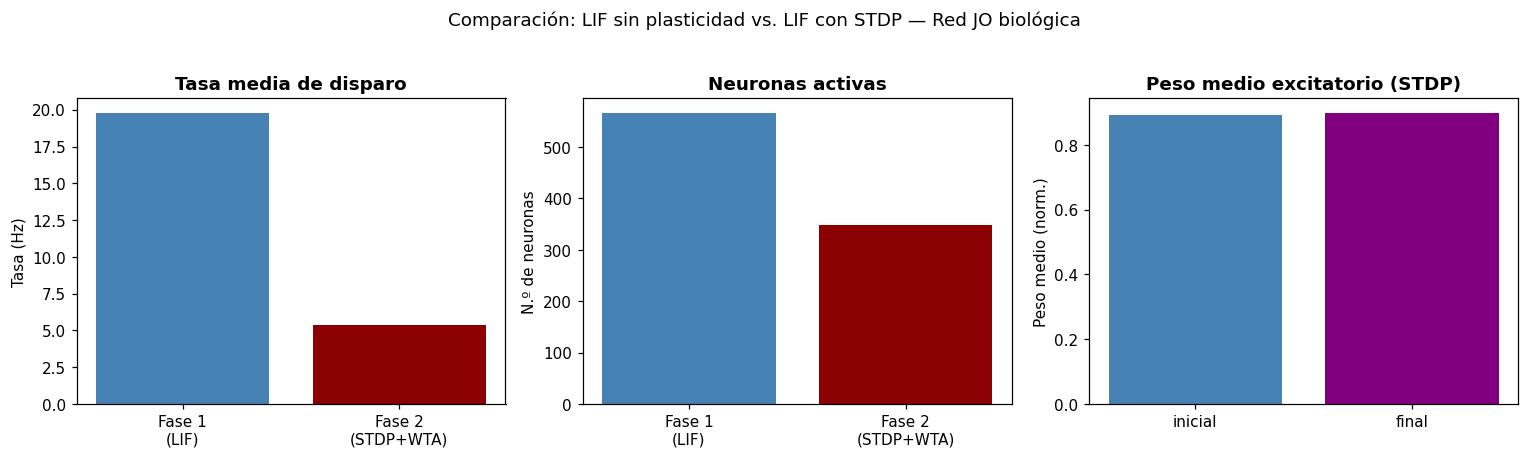

Figure saved: outputs/fig04_static_vs_stdp_comparison.png


In [10]:
m1 = json.load(open(ART_DIR/'metrics_static_weights.json'))
m2 = json.load(open(ART_DIR/'metrics_stdp.json'))

print('=' * 64)
print(f"{'METRIC':<34}{'STATIC (LIF)':>14}{'WITH STDP':>16}")
print('=' * 64)
print(f"{'Total spikes':<34}{m1['total_spikes']:>14}{m2['total_spikes']:>16}")
print(f"{'Mean rate (Hz)':<34}{m1['mean_rate_hz']:>14.2f}{m2['mean_rate_hz']:>16.2f}")
print(f"{'Active neurons':<34}{m1['active_neurons']:>14}{m2['active_neurons']:>16}")
print(f"{'% active':<34}{m1['active_percent']:>14.1f}{m2['active_percent']:>16.1f}")
print('=' * 64)
print('\nEffect of STDP on the excitatory weights (STDP run):')
print(f"  mean absolute change |Δw|      : {m2['mean_abs_dw']:.4f}")
print(f"  potentiated synapses (Δw>0)    : {m2['synapses_potentiated']:,}")
print(f"  depressed synapses   (Δw<0)    : {m2['synapses_depressed']:,}")
print(f"  modified synapses (|Δw|>0.01)  : {m2['synapses_modified_pct']:.1f}%")
print('=' * 64)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
labels = ['Static weights\n(LIF)', 'STDP + WTA']
ax[0].bar(labels, [m1['mean_rate_hz'], m2['mean_rate_hz']], color=['steelblue', 'darkred'])
ax[0].set(ylabel='Rate (Hz)', title='Mean firing rate')
ax[1].bar(labels, [m1['active_neurons'], m2['active_neurons']], color=['steelblue', 'darkred'])
ax[1].set(ylabel='Number of neurons', title='Active neurons')
ax[2].bar(['before', 'after'], [m2['mean_weight_before'], m2['mean_weight_after']],
          color=['steelblue', 'purple'])
ax[2].set(ylabel='Mean weight (norm.)', title='Mean excitatory weight (STDP)')
fig.suptitle('Comparison: LIF with static weights vs. LIF with STDP — biological JO network', y=1.03)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig04_static_vs_stdp_comparison.png'); plt.show()
print('Figure saved: outputs/fig04_static_vs_stdp_comparison.png')

## 6. What the preliminary experiment established

**Validations obtained**

1. **The JO subgraph is extracted correctly.** The biological subgraph produced by the EDA (1,239 neurons, 20,059 connections) loads without errors, carries its functional polarity, and translates cleanly into the index format Brian2 expects.
2. **The LIF simulation is coherent.** With static weights the biological network produces structured spatiotemporal activity, a raster that is anything but uniform, reproducing the baseline condition of Shiu et al. (2024).
3. **STDP has a measurable effect.** Adding plasticity and WTA on the same topology reorganizes the synaptic weights, shifting both the mean and the shape of the distribution, and it changes the firing dynamics.

**What this means for the main experiment**

- The pipeline *(connectome → graph → Brian2 → LIF → STDP)* is validated end to end.
- Metrics from the static-weight run give us the baseline against which the **Erdős–Rényi** control network, matched in statistical properties, will be compared under the same STDP regime.
- Next comes replacing the fixed-rate Poisson input with **real auditory stimuli encoded as spike trains**, and then measuring **classification accuracy**, which is the central research question of the project.

> **Calibration note.** Should the activity come out silent or saturated, the first thing to adjust is `w_scale` and `w_input`, the current scaling factors. Nothing else in the notebook needs to change.
